# Missing-data audit: first pass

This notebook measures missing data in the original daily buoy readings. It does not fill values, change the source file, assign buoy IDs, or choose the team's final modeling label.

**Review scope:** missingness by column, year, and temporary geographic area. Tina's site IDs are still in progress, so the area results are **not** missingness by buoy.

Import the tools for tables and simple charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

Read the original file, not the separate filled-data export. This path works when Jupyter starts from either the repository root or its notebooks folder.

In [2]:
candidates = [Path("../data/el_nino_features.csv"), Path("data/el_nino_features.csv")]
source = next((path for path in candidates if path.exists()), None)
if source is None:
    raise FileNotFoundError("Could not find data/el_nino_features.csv")
raw = pd.read_csv(source)
print(f"Source: {source} | Daily readings: {len(raw):,}")
display(raw.head(3))

Source: ..\data\el_nino_features.csv | Daily readings: 178,080


,year,month,day,date,latitude,longitude,zon_winds,mer_winds,humidity,air_temp,ss_temp
0,80,3,7,800307,-0.02,-109.46,-6.8,0.7,NaN,26.14,26.24
1,80,3,8,800308,-0.02,-109.46,-4.9,1.1,NaN,25.66,25.97
2,80,3,9,800309,-0.02,-109.46,-4.5,2.2,NaN,25.69,25.28


Count missing values in every source column. The percentage uses all daily rows as its denominator.

In [3]:
column_missing = pd.DataFrame({
    "readings": len(raw),
    "missing": raw.isna().sum(),
})
column_missing["missing_pct"] = 100 * column_missing["missing"] / column_missing["readings"]
display(column_missing.sort_values("missing_pct", ascending=False).round(1))

,readings,missing,missing_pct
humidity,178080,65761,36.9
zon_winds,178080,25163,14.1
mer_winds,178080,25162,14.1
air_temp,178080,18237,10.2
ss_temp,178080,17007,9.6
year,178080,0,0.0
month,178080,0,0.0
day,178080,0,0.0
longitude,178080,0,0.0
date,178080,0,0.0


Compare missingness by year for the five sensor measurements. The source years 80–98 are displayed as 1980–1998 here; this does not alter the data file or replace Taniya's date work.

In [4]:
measurements = ["zon_winds", "mer_winds", "humidity", "air_temp", "ss_temp"]
audit = raw.copy()
audit["year_full"] = audit["year"] + 1900
year_missing = audit[measurements].isna().groupby(audit["year_full"]).mean() * 100
year_missing.insert(0, "readings", audit.groupby("year_full").size())
display(year_missing.round(1))

,readings,zon_winds,mer_winds,humidity,air_temp,ss_temp
year_full,,,,,,
1980,166,0.0,0.0,100.0,0.0,4.8
1981,545,0.0,0.0,100.0,0.0,40.7
1982,505,2.4,2.4,100.0,0.0,14.7
1983,406,27.6,27.6,100.0,0.5,15.5
1984,947,6.5,6.5,100.0,4.6,26.7
1985,1684,44.2,44.2,100.0,15.7,29.5
1986,3780,29.4,29.4,100.0,16.5,38.5
1987,4688,5.5,5.5,100.0,14.9,32.7
1988,6136,12.1,12.1,100.0,13.2,19.9


Plot yearly percentages to see whether gaps are concentrated in particular periods.

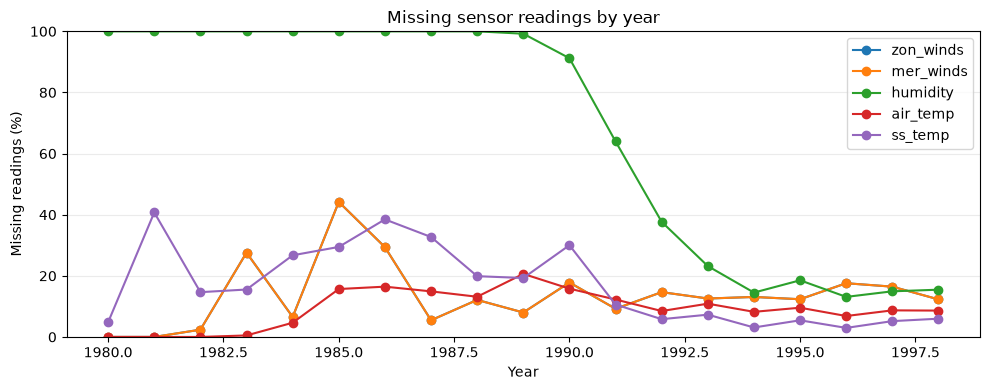

In [5]:
ax = year_missing[measurements].plot(figsize=(10, 4), marker="o")
ax.set(title="Missing sensor readings by year", xlabel="Year", ylabel="Missing readings (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

For exploration only, group coordinates into 5° latitude × 10° longitude areas. Longitude is converted to 0–360° east so readings near the date line stay comparable. Each label gives the *start* of an area. An area can contain multiple buoys; it is not a site ID.

In [6]:
audit["lat_band"] = np.floor(audit["latitude"] / 5).astype(int) * 5
audit["lon_east_band"] = np.floor(audit["longitude"].mod(360) / 10).astype(int) * 10
area_keys = ["lat_band", "lon_east_band"]
print("Temporary areas:", audit[area_keys].drop_duplicates().shape[0])

Temporary areas: 51


Calculate the number of readings and missing percentage for each sensor in each temporary area. Show the 12 areas with the most rows first; row counts matter when judging a percentage.

In [7]:
area_readings = audit.groupby(area_keys).size().rename("readings")
area_missing = audit[measurements].isna().groupby(
    [audit[key] for key in area_keys]
).mean().mul(100)
area_summary = pd.concat([area_readings, area_missing], axis=1)
display(area_summary.sort_values("readings", ascending=False).head(12).round(1))

readings  zon_winds  mer_winds  humidity  air_temp  \
lat_band lon_east_band                                                       
-5       160               11430       17.6       17.6      64.4      24.9   
         180                8183       11.3       11.3       8.1       1.8   
 0       200                7517        5.1        5.1      36.5       4.8   
         160                7208       14.6       14.6      39.0      13.2   
-5       250                6754       10.4       10.4      47.2       3.6   
 0       180                6726        5.4        5.4      24.5      13.4   
 5       160                6433       11.5       11.5      35.9      10.8   
-5       230                6328        8.5        8.5      41.3      16.7   
 5       210                6026       16.7       16.7      48.4       5.3   
 0       150                5988       17.4       17.4      29.2       9.1   
-5       220                5983        4.6        4.6      38.4       4.3   
 0       240                5866       15.2       15.2      59.8      11.8   

                        ss_temp  
lat_band lon_east_band           
-5       160               31.0  
         180                2.4  
 0       200               27.4  
         160                9.3  
-5       250                3.8  
 0       180               25.1  
 5       160                1.3  
-5       230               10.5  
 5       210                4.8  
 0       150               18.5  
-5       220                5.3  
 0       240                4.5

For the 12 most-sampled areas, compare humidity gaps by year. Blank cells mean fewer than 30 readings in that area-year (or no readings), not 0% missing. This is a temporary area view while Tina's buoy IDs are pending.
* We collect the readings here, and the values in each row for each column represents how much of that data was missing from those readings.
- Ex: In Latitude -5 and Longitude 160 (first row) there were 11430 readings of data from 1980 - 1998. Of that, the humidity column was 64.4% missing, and zon_winds was missing 17.6% of the time.

In [8]:
top_areas = area_readings.nlargest(12).index
area_year_keys = area_keys + ["year_full"]
area_year_counts = audit.groupby(area_year_keys).size().unstack("year_full")
area_year_humidity = audit["humidity"].isna().groupby(
    [audit[key] for key in area_year_keys]
).mean().mul(100).unstack("year_full")
heatmap_data = area_year_humidity.reindex(top_areas).where(
    area_year_counts.reindex(top_areas) >= 30
)

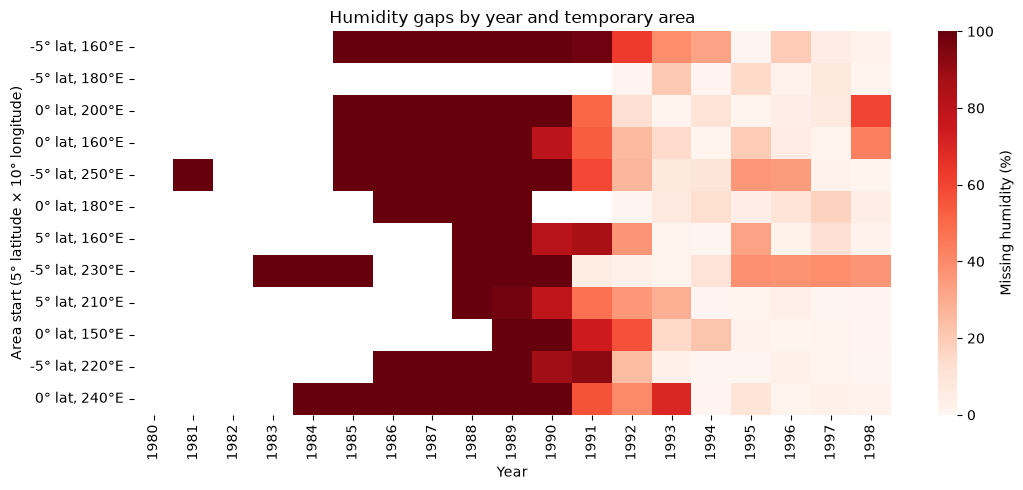

In [9]:
area_labels = [f"{lat}° lat, {lon}°E" for lat, lon in heatmap_data.index]
plt.figure(figsize=(11, 5))
sns.heatmap(heatmap_data, cmap="Reds", vmin=0, vmax=100,
            yticklabels=area_labels, cbar_kws={"label": "Missing humidity (%)"})
plt.title("Humidity gaps by year and temporary area")
plt.xlabel("Year")
plt.ylabel("Area start (5° latitude × 10° longitude)")
plt.tight_layout()
plt.show()

Humidity was missing from most recorded readings in the displayed areas before 1991, then generally became more available. Each row represents a geographic area, with darker red showing a higher percentage of missing humidity values. Blank cells indicate fewer than 30 recorded rows or no rows for that year, so they do not confirm a sensor failure, just less available data from that area.

## Other sensor gaps by area

This map combines zonal wind, meridional wind, air temperature, and SST. **Humidity is excluded.** Each absent sensor value counts once, so a daily row can contribute 0–4 missing values. Darker areas have more missing values in total; the table also shows the missing percentage so areas with more readings are not mistaken for worse-quality areas. These are temporary geographic areas, not buoy IDs.

In [10]:
other_sensors = ["zon_winds", "mer_winds", "air_temp", "ss_temp"]
# Count how many of the four sensor values are absent in each daily row.
audit["other_missing_count"] = audit[other_sensors].isna().sum(axis=1)
area_other_missing = audit.groupby(area_keys)["other_missing_count"].sum()
# Four possible sensor values per reading form the percentage denominator.
area_other_pct = 100 * area_other_missing / (4 * area_readings)

Show the ten areas with the most missing sensor values. Compare the count with the percentage and number of readings before drawing conclusions.

In [11]:
area_other_summary = pd.DataFrame({
    "readings": area_readings,
    "missing_values": area_other_missing,
    "missing_pct_of_four": area_other_pct,
})
display(area_other_summary.sort_values("missing_values", ascending=False).head(10).round(1))

readings  missing_values  missing_pct_of_four
lat_band lon_east_band                                               
-5       160               11430           10417                 22.8
 0       140                4537            4208                 23.2
         130                2445            3953                 40.4
         160                7208            3730                 12.9
         150                5988            3728                 15.6
         180                6726            3317                 12.3
         200                7517            3181                 10.6
-5       230                6328            2799                 11.1
 0       240                5866            2742                 11.7
-10      180                4585            2650                 14.4

Place those counts on a latitude–longitude grid. A blank square means no readings were recorded in that area; it does not mean zero missing values.

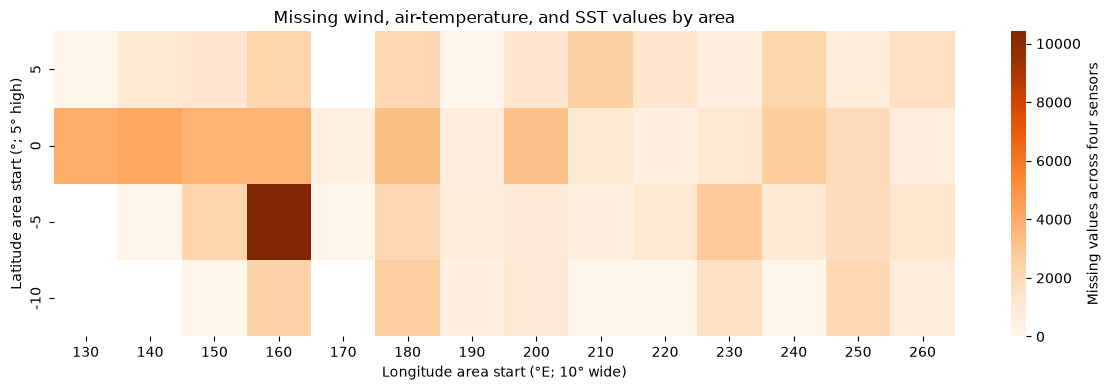

In [12]:
# North is at the top; each square is one temporary 5° × 10° area.
area_map = area_other_missing.unstack("lon_east_band").sort_index(ascending=False)
plt.figure(figsize=(12, 4))
ax = sns.heatmap(area_map, cmap="Oranges", mask=area_map.isna(),
                 cbar_kws={"label": "Missing values across four sensors"})
ax.set(title="Missing wind, air-temperature, and SST values by area",
       xlabel="Longitude area start (°E; 10° wide)",
       ylabel="Latitude area start (°; 5° high)")
plt.tight_layout()
plt.show()

## How long do gaps last?

We count runs (consecutive calendar days) separately for each sensor and temporary area. A sensor gap requires recorded rows but **no measured value for that sensor anywhere in the area that day**. A day with at least one measured value breaks the run, even if other rows are missing.

Days with **no recorded rows** form a separate coverage gap and also break sensor-gap runs. We only examine dates between each area's first and last recorded day. These are area-level availability gaps; measurements from another buoy in the same area can hide a buoy's individual gap.

In [13]:
# Make dates only for this audit, using the original year/month/day fields.
audit["audit_date"] = pd.to_datetime({
    "year": audit["year_full"],
    "month": audit["month"],
    "day": audit["day"],
}, errors="raise")

Count measured values for each sensor on each recorded area-day. A count of zero means that sensor was missing in every row for that day; row_count counts all recorded rows.

In [14]:
daily_keys = area_keys + ["audit_date"]
daily_counts = audit.groupby(daily_keys)[measurements].count()
daily_counts["row_count"] = audit.groupby(daily_keys).size()
display(daily_counts.head())

zon_winds  mer_winds  humidity  air_temp  \
lat_band lon_east_band audit_date                                             
-10      150           1992-01-17          0          0         0         1   
                       1992-02-22          0          0         0         1   
                       1992-02-24          0          0         0         1   
                       1992-03-14          0          0         0         1   
                       1992-03-23          0          0         0         1   

                                   ss_temp  row_count  
lat_band lon_east_band audit_date                      
-10      150           1992-01-17        1          1  
                       1992-02-22        1          1  
                       1992-02-24        1          1  
                       1992-03-14        1          1  
                       1992-03-23        1          1

This helper groups adjacent True days into a run, then records its start, end, and length. It will be used on a complete daily calendar so a skipped date cannot silently join two runs.

In [15]:
def find_day_runs(flag):
    # A new group starts whenever the flag changes between True and False.
    run_id = flag.ne(flag.shift(fill_value=False)).cumsum()
    days = pd.DataFrame({"date": flag.index, "run_id": run_id.to_numpy()})
    # Keep only the flagged days; each group is one consecutive-day run.
    return (days.loc[flag.to_numpy()].groupby("run_id")
            .agg(start=("date", "min"), end=("date", "max"),
                 days=("date", "size")).reset_index(drop=True))

Build a full calendar for each area, then find sensor and coverage runs. A run touching the area's first or last day may extend beyond the recorded window, so we mark that boundary in the results.

In [16]:
run_tables = []
for area, recorded in daily_counts.groupby(level=area_keys):
    daily = recorded.droplevel(area_keys).sort_index()
    calendar = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
    daily = daily.reindex(calendar)
    # No-row dates become NaN, not zero, so they do not become sensor gaps.
    flags = daily[measurements].eq(0)
    flags["no_rows"] = daily["row_count"].isna()
    for sensor in flags.columns:
        runs = find_day_runs(flags[sensor])
        runs["sensor"] = sensor
        runs["lat_band"], runs["lon_east_band"] = area
        runs["touches_area_boundary"] = (runs.start.eq(calendar[0])
                                         | runs.end.eq(calendar[-1]))
        run_tables.append(runs)
gap_runs = pd.concat(run_tables, ignore_index=True)

Compare the number of sensor gaps, their typical length, and their longest recorded length. A gap is counted once regardless of how many days it lasts. This table pools runs across areas; it does not count missing daily source rows.

In [17]:
sensor_runs = gap_runs.loc[gap_runs["sensor"].isin(measurements)].copy()
coverage_runs = gap_runs.loc[gap_runs["sensor"].eq("no_rows")].copy()
gap_summary = (sensor_runs.groupby("sensor")["days"]
               .agg(gaps="size", total_gap_days="sum",
                    median_days="median", longest_days="max")
               .reindex(measurements))
display(gap_summary)
print("Separate no-row runs:", len(coverage_runs))

,gaps,total_gap_days,median_days,longest_days
sensor,,,,
zon_winds,1453,11892,1.0,462
mer_winds,1453,11891,1.0,462
humidity,2166,39251,1.0,2096
air_temp,1177,7824,1.0,802
ss_temp,890,9137,1.0,892


Separate no-row runs: 2657


Review the ten longest sensor gaps with their dates and area coordinates. Boundary-marked runs are limited by the available record.

In [18]:
display(sensor_runs.sort_values("days", ascending=False)
        [["sensor", "lat_band", "lon_east_band", "start", "end",
          "days", "touches_area_boundary"]].head(10))

,sensor,lat_band,lon_east_band,start,end,days,touches_area_boundary
1964,humidity,-5,160,1985-07-05,1991-03-31,2096,True
5187,ss_temp,0,200,1985-09-13,1988-02-21,892,False
5120,humidity,0,200,1985-09-13,1988-02-21,892,False
4706,humidity,0,180,1987-02-23,1989-05-04,802,False
4734,ss_temp,0,180,1987-02-23,1989-05-04,802,False
4720,air_temp,0,180,1987-02-23,1989-05-04,802,False
4268,humidity,0,150,1989-05-26,1991-07-11,777,True
4338,ss_temp,0,150,1989-05-26,1991-07-11,777,True
5123,humidity,0,200,1988-10-08,1990-07-09,640,False
5190,ss_temp,0,200,1988-10-08,1990-07-09,640,False


Group the lengths into readable ranges. The first Matplotlib graph counts sensor gaps in each range; humidity is included as its own sensor. The second graph counts days-with-no-rows runs separately.

In [19]:
duration_labels = ["1 day", "2–7 days", "8–30 days", "31–90 days", "91+ days"]
duration_bins = [0, 1, 7, 30, 90, np.inf]
sensor_runs["duration"] = pd.cut(sensor_runs["days"], duration_bins,
                                  labels=duration_labels)
coverage_runs["duration"] = pd.cut(coverage_runs["days"], duration_bins,
                                    labels=duration_labels)
sensor_gap_counts = pd.crosstab(sensor_runs["duration"], sensor_runs["sensor"])
sensor_gap_counts = sensor_gap_counts.reindex(
    index=duration_labels, columns=measurements, fill_value=0)

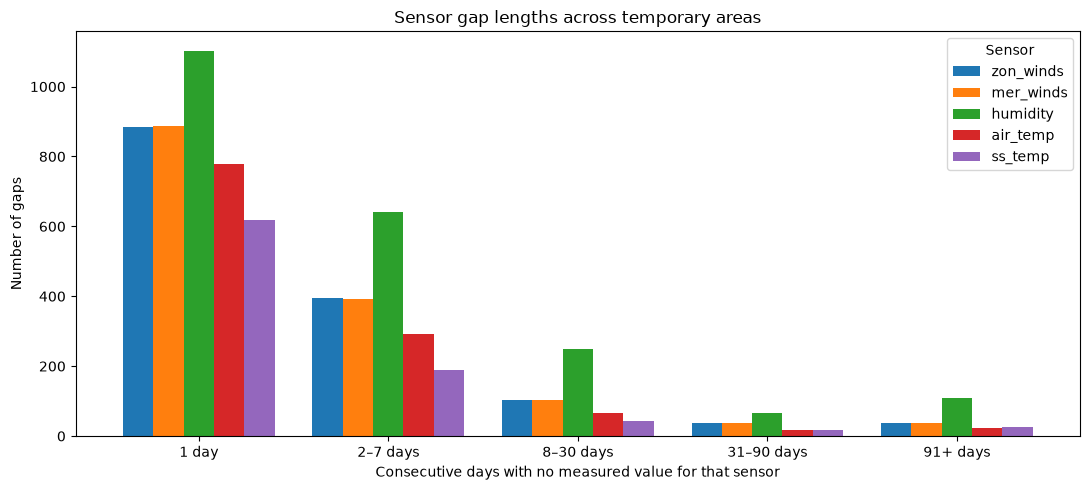

In [20]:
# Pandas draws this grouped bar chart through Matplotlib.
ax = sensor_gap_counts.plot.bar(figsize=(11, 5), width=0.8)
ax.set(title="Sensor gap lengths across temporary areas",
       xlabel="Consecutive days with no measured value for that sensor",
       ylabel="Number of gaps")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Sensor")
plt.tight_layout()
plt.show()

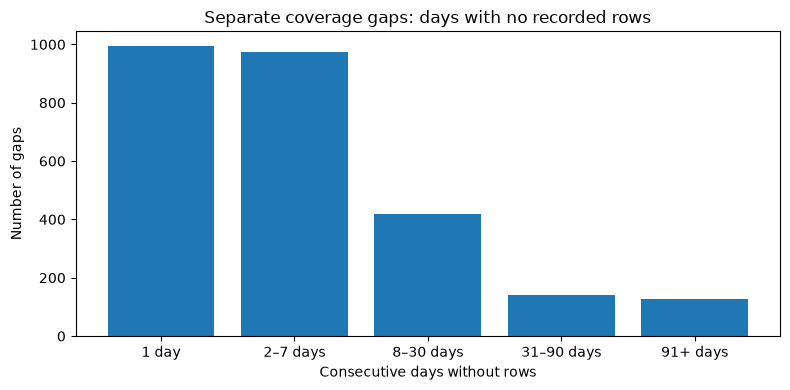

In [21]:
coverage_gap_counts = coverage_runs["duration"].value_counts().reindex(
    duration_labels, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(duration_labels, coverage_gap_counts)
ax.set(title="Separate coverage gaps: days with no recorded rows",
       xlabel="Consecutive days without rows", ylabel="Number of gaps")
plt.tight_layout()
plt.show()

## What this means for the next test

Use these lengths to design realistic stretches of hidden measured values when testing fill methods, rather than hiding only isolated random values. Review long gaps and boundary-marked runs separately. The graphs describe availability and do not prove why a value is absent or which fill method works best.

The final cleaned CSV must preserve the original column names and order. Any proposed extra training columns need evidence and Jon's review first. Audit-only dates, area bands, and gap fields stay in notebook memory in this step.

## For review

- These results describe **where measurements are absent**; they do not show why or decide how to fill them.
- Final missingness **by buoy** depends on Tina's agreed site IDs. When available, rerun the same counts using her ID column rather than these temporary areas.
- The gap-length audit now separates sensor gaps from dates without rows. Next, test proposed variable-specific, time-aware fill rules on stretches of held-out observed readings. Do not treat this notebook as validation of the existing filled CSV.